<!-- Aula 1 - Prof. Dr. Marcos Hoffmann -->
# <font color='blue'>MLOps e Ciclo de Vida de Modelos de Machine Learning</font>
## <font color='blue'>Prof. Dr. Marcos Hoffmann - Aula 1</font>
### <font color='blue'>MLOps Stack Para Otimização de Hiperparâmetros com MLflow e Optuna</font>

## Objetivo da Aula

Neste projeto vamos construir, de ponta a ponta, um **stack de MLOps** para treinar um modelo de regressão que **prevê a demanda de um produto** (em kg) a partir de variáveis como temperatura, preço, promoções e marketing.

O foco não é apenas treinar um modelo, mas **gerenciar o ciclo de vida** dele:

| Etapa | Ferramenta | O que faz |
|---|---|---|
| Rastreamento de experimentos | **MLflow Tracking** | Registra parâmetros, métricas, gráficos e modelos de cada execução |
| Otimização de hiperparâmetros | **Optuna** | Busca automaticamente a melhor combinação de hiperparâmetros |
| Algoritmo de Machine Learning | **XGBoost** | Modelo de *gradient boosting* usado na regressão |
| Versionamento do modelo | **MLflow Models** | Salva o modelo treinado em um formato padronizado e recarregável |

### Fluxo do notebook

1. Preparar o ambiente e iniciar o servidor MLflow
2. Carregar e entender os dados e o dicionário de dados
3. Criar funções de visualização (que também serão salvas como artefatos no MLflow)
4. Criar o experimento no MLflow
5. Pré-processar os dados (treino/validação)
6. Definir a função objetivo do Optuna e o *callback* de acompanhamento
7. Executar a otimização registrando tudo no MLflow
8. Carregar o melhor modelo a partir do MLflow e fazer inferência

> **Por que MLOps?** Sem rastreamento, depois de dezenas de testes é praticamente impossível saber *qual* combinação de parâmetros gerou *qual* resultado. O MLflow resolve isso guardando tudo de forma organizada e reprodutível.

## Instalação, Carregamento e Gerenciamento de Pacotes

In [1]:
# Para atualizar um pacote, execute o comando abaixo no terminal ou prompt de comando:
# pip install -U nome_pacote

# Para instalar a versão exata de um pacote, execute o comando abaixo no terminal ou prompt de comando:
# pip install nome_pacote==versão_desejada

# Depois de instalar ou atualizar o pacote, reinicie o jupyter notebook.

# Instala o pacote watermark. 
# Esse pacote é usado para gravar as versões de outros pacotes usados neste jupyter notebook.
!pip install -q -U watermark

Não é necessário instalar os pacotes abaixo, pois eles já estão no arquivo requirements.txt. Leia as instruções no arquivo LEIAME.txt.

> **Dica:** o prefixo `!` executa um comando do terminal dentro do Jupyter. O parâmetro `-q` (*quiet*) reduz as mensagens exibidas durante a instalação.
>
> **Atenção à versão do MLflow:** este material foi ajustado para o **MLflow 3.x**. Algumas APIs mudaram em relação ao MLflow 2.x (por exemplo, `log_model` agora usa o parâmetro `name` em vez de `artifact_path`). Veja as observações na seção de execução do experimento.

In [2]:
!pip install -q optuna


In [3]:
!pip install -q mlflow

In [4]:
!pip install -q xgboost

In [5]:
# Imports
import json                       # Leitura do dicionário de dados (arquivo .json)
import math                       # Funções matemáticas (ex.: raiz quadrada para calcular o RMSE)
import sklearn                    # Biblioteca de Machine Learning (métricas e divisão de dados)
import optuna                     # Otimização automática de hiperparâmetros
import mlflow                     # Rastreamento de experimentos e gerenciamento de modelos
import numpy as np                # Computação numérica
import pandas as pd               # Manipulação de dados tabulares (DataFrames)
import xgboost as xgb             # Algoritmo de gradient boosting usado como modelo
import matplotlib.pyplot as plt   # Criação de gráficos
import seaborn as sns             # Estilos e paletas para gráficos estatísticos
from sklearn.metrics import mean_squared_error          # Métrica MSE (erro quadrático médio)
from sklearn.model_selection import train_test_split    # Divisão em treino e validação
from datetime import datetime, timedelta
import warnings
warnings.filterwarnings('ignore') # Oculta avisos para deixar a saída mais limpa (em produção, avalie os avisos!)

In [6]:
# Versões dos pacotes usados neste jupyter notebook
%reload_ext watermark
%watermark -a "Prof. Dr. Marcos Hoffmann" 

Author: Prof. Dr. Marcos Hoffmann



## Inicializando o Servidor MLflow

Abra um prompt de comando ou terminal, navegue até a pasta do projeto, ative o ambiente virtual (instruções no LEIAME.txt) e digite o comando abaixo:

```bash
mlflow server --host 127.0.0.1 --port 8282
```

**Entendendo o comando:**

- `--host 127.0.0.1`: o servidor fica acessível apenas na sua própria máquina (*localhost*).
- `--port 8282`: porta onde o servidor vai "escutar" as requisições.

**O que o servidor cria na pasta do projeto:**

- `mlflow.db` → **backend store**: banco SQLite com os metadados (experimentos, execuções, parâmetros, métricas e tags).
- `mlartifacts/` → **artifact store**: arquivos gerados (gráficos, modelos serializados, exemplos de entrada etc.).

> **Importante:** o terminal com o servidor deve **permanecer aberto** durante toda a aula. Se ele for fechado, as células que usam o MLflow vão falhar com o erro `ConnectionRefusedError: [Errno 61] Connection refused`.

> Agora conectamos no servidor MLflow:

In [7]:
# Define o endereço do servidor MLflow que vai receber os registros (parâmetros, métricas, artefatos e modelos).
# Esse endereço deve ser o mesmo usado no comando "mlflow server" (host e porta).
mlflow.set_tracking_uri("http://127.0.0.1:8282")

Acesse a url acima a partir de outra aba no seu navegador: http://127.0.0.1:8282

## Carregando e Compreendendo os Dados

O dataset contém **5.000 registros diários** de vendas de um produto. A variável que queremos prever (**variável alvo**) é a `demanda`. As demais colunas são as **variáveis preditoras** (*features*).

Antes de modelar, sempre precisamos responder: quantas linhas e colunas existem? Quais são os tipos de dados? Há valores ausentes? Quais são as escalas das variáveis?

In [8]:
# Carrega o dataset (o arquivo deve estar na mesma pasta do notebook)
df = pd.read_csv("dataset.csv")

In [9]:
# Shape: (número de linhas, número de colunas)
df.shape

(5000, 11)

In [10]:
# Amostra dos dados: exibe as 5 primeiras linhas
df.head()

,data,temperatura_media,precipitacao,fim_de_semana,feriado,preco_por_kg,promocao,demanda,demanda_dos_dias_anteriores,preco_por_kg_do_concorrente,intensidade_de_marketing
0,2010-10-18 09:16:07.883826,30.584727,1.199291,0,0,1.726258,1,1051.375336,1051.276659,1.935346,0.098677
1,2010-10-19 09:16:07.883825,15.465069,1.037626,0,0,0.576471,1,1106.855943,1051.276659,2.344720,0.019318
2,2010-10-20 09:16:07.883824,10.786525,5.656089,0,0,2.513328,1,1008.304909,1106.836626,0.998803,0.409485
3,2010-10-21 09:16:07.883823,23.648154,12.030937,0,0,1.839225,1,999.833810,1057.895424,0.761740,0.872803
4,2010-10-22 09:16:07.883822,13.861391,4.303812,0,0,1.531772,1,1183.949061,1048.961007,2.123436,0.820779


In [11]:
# Tipos dos dados e contagem de valores não nulos de cada coluna
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 11 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   data                         5000 non-null   object 
 1   temperatura_media            5000 non-null   float64
 2   precipitacao                 5000 non-null   float64
 3   fim_de_semana                5000 non-null   int64  
 4   feriado                      5000 non-null   int64  
 5   preco_por_kg                 5000 non-null   float64
 6   promocao                     5000 non-null   int64  
 7   demanda                      5000 non-null   float64
 8   demanda_dos_dias_anteriores  5000 non-null   float64
 9   preco_por_kg_do_concorrente  5000 non-null   float64
 10  intensidade_de_marketing     5000 non-null   float64
dtypes: float64(7), int64(3), object(1)
memory usage: 429.8+ KB


In [12]:
# Vamos ajustar a coluna de data para o tipo correto
# A coluna foi lida como texto (object). Convertê-la para datetime permite operações com datas.
df['data'] = pd.to_datetime(df['data'])

In [13]:
# Tipos dos dados (confirme que a coluna "data" agora é datetime64)
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 11 columns):
 #   Column                       Non-Null Count  Dtype         
---  ------                       --------------  -----         
 0   data                         5000 non-null   datetime64[ns]
 1   temperatura_media            5000 non-null   float64       
 2   precipitacao                 5000 non-null   float64       
 3   fim_de_semana                5000 non-null   int64         
 4   feriado                      5000 non-null   int64         
 5   preco_por_kg                 5000 non-null   float64       
 6   promocao                     5000 non-null   int64         
 7   demanda                      5000 non-null   float64       
 8   demanda_dos_dias_anteriores  5000 non-null   float64       
 9   preco_por_kg_do_concorrente  5000 non-null   float64       
 10  intensidade_de_marketing     5000 non-null   float64       
dtypes: datetime64[ns](1), float64(7), int64(3)


In [14]:
# Resumo estatístico: média, desvio padrão, mínimo, quartis e máximo das colunas numéricas
df.describe()

,data,temperatura_media,precipitacao,fim_de_semana,feriado,preco_por_kg,promocao,demanda,demanda_dos_dias_anteriores,preco_por_kg_do_concorrente,intensidade_de_marketing
count,5000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,2017-08-21 21:16:07.881014528,22.433182,4.962877,0.285600,0.033000,1.758228,0.289000,1258.452333,1282.446665,1.769682,0.848173
min,2010-10-18 09:16:07.883826,10.002439,0.000071,0.000000,0.000000,0.500360,0.000000,707.952882,757.216503,0.500754,0.019318
25%,2014-03-21 03:16:07.882367232,16.311898,1.440718,0.000000,0.000000,1.134110,0.000000,1066.040653,1089.993191,1.160719,0.773080
50%,2017-08-21 21:16:07.881031424,22.400265,3.520515,0.000000,0.000000,1.776194,0.000000,1222.237635,1244.619215,1.764809,0.848107
75%,2021-01-22 15:16:07.879706624,28.570768,6.805668,1.000000,0.000000,2.383638,1.000000,1422.792698,1445.791858,2.401827,0.928536
max,2024-06-25 09:16:07.878116,34.995334,40.072693,1.000000,1.000000,2.999606,1.000000,2183.463942,2182.608701,2.999847,0.999979
std,NaN,7.146610,4.932382,0.451745,0.178654,0.725334,0.453343,253.240475,249.087488,0.721041,0.093135


> **Para refletir:** observe as escalas das variáveis no resumo estatístico. Modelos baseados em árvores (como o XGBoost com `gbtree`) não exigem padronização das variáveis, mas modelos lineares (como o `gblinear`) podem ser sensíveis a escalas muito diferentes.

<!-- Projeto Desenvolvido na Data Science Academy - www.datascienceacademy.com.br -->
## Carregando e Compreendendo os Metadados (Dicionário)

O **dicionário de dados** descreve o significado e o tipo de cada coluna. Ele é parte essencial da documentação de um projeto de MLOps: garante que todos (cientistas de dados, engenheiros e área de negócio) interpretem as variáveis da mesma forma.

In [15]:
# Carrega o arquivo JSON com a descrição de cada variável
with open('dicionario_de_dados.json', 'r') as arquivo:
    dicionario_de_dados = json.load(arquivo)

In [16]:
# Cria um DataFrame a partir do dicionário de metadados
df_dict = pd.DataFrame.from_dict(dicionario_de_dados, orient = 'index')

In [17]:
# Não truncar colunas no Pandas (exibe as descrições completas do dicionário)
pd.set_option('display.max_colwidth', None)

In [18]:
# Exibe o dicionário de dados em formato de tabela
df_dict

,descrição,tipo
data,Data e hora em que os dados foram registrados.,datetime
temperatura_media,Temperatura média registrada na data.,float
precipitacao,Quantidade de precipitação registrada na data.,float
fim_de_semana,Indica se o dia é um fim de semana (1) ou não (0).,int
feriado,Indica se o dia é um feriado (1) ou não (0).,int
preco_por_kg,Preço por kg do produto vendido.,float
promocao,Indica se havia uma promoção ativa (1) ou não (0).,int
demanda,Demanda do produto na data.,float
demanda_dos_dias_anteriores,Demanda do produto no dia anterior.,float
preco_por_kg_do_concorrente,Preço por kg do produto oferecido por um concorrente.,float


<!-- Projeto Desenvolvido na Data Science Academy - www.datascienceacademy.com.br -->
## Funções de Exploração e Visualização dos Dados Para o Experimento

As funções abaixo geram gráficos que ajudam a **entender os dados e avaliar o modelo**. Repare que todas elas **retornam o objeto `fig`** (a figura do Matplotlib) em vez de apenas exibir o gráfico. Isso é proposital: mais adiante, vamos enviar essas figuras ao MLflow com `mlflow.log_figure()`, para que cada execução fique documentada com seus próprios gráficos.

| Função | Objetivo |
|---|---|
| `plot_corr_demanda` | Mostra a correlação de cada variável preditora com a demanda |
| `plot_residuos` | Mostra os erros do modelo (resíduos) em relação aos valores reais |
| `plot_feature_importance` | Mostra quais variáveis o modelo considerou mais importantes |

In [19]:
# Função para o plot da correlação das variáveis preditoras com a variável alvo (demanda)
def plot_corr_demanda(df, save_path = None):

    # Calcula as correlações das variáveis com a demanda, exceto a própria demanda
    correlations = df.corr()["demanda"].drop("demanda").sort_values()

    # Define uma paleta de cores divergentes
    colors = sns.diverging_palette(10, 130, as_cmap = True)
    
    # Mapeia as cores às correlações
    color_mapped = correlations.map(colors)

    # Define o estilo do gráfico
    sns.set_style("darkgrid", {"axes.facecolor": "#eaeaf2", "grid.linewidth": 1.5})

    # Cria a figura do plot com tamanho definido
    fig = plt.figure(figsize = (12, 8))
    
    # Cria um gráfico de barras horizontais para as correlações
    plt.barh(correlations.index, correlations.values, color = color_mapped)

    # Define o título e os rótulos dos eixos do gráfico
    plt.title("Correlação com Demanda", fontsize = 16)
    plt.xlabel("Coeficiente de Correlação", fontsize = 14)
    plt.ylabel("Variável", fontsize = 14)
    plt.xticks(fontsize = 12)
    plt.yticks(fontsize = 12)
    plt.grid(axis="x")

    # Ajusta o layout para evitar sobreposição
    plt.tight_layout()

    # Salva o gráfico como um arquivo PNG, se um caminho for fornecido
    if save_path:
        plt.savefig(save_path, format = "png", dpi = 600)

    # Fecha a figura para liberar memória
    plt.close(fig)

    # Retorna a figura criada
    return fig

In [20]:
# Executa a função
grafico1 = plot_corr_demanda(df)

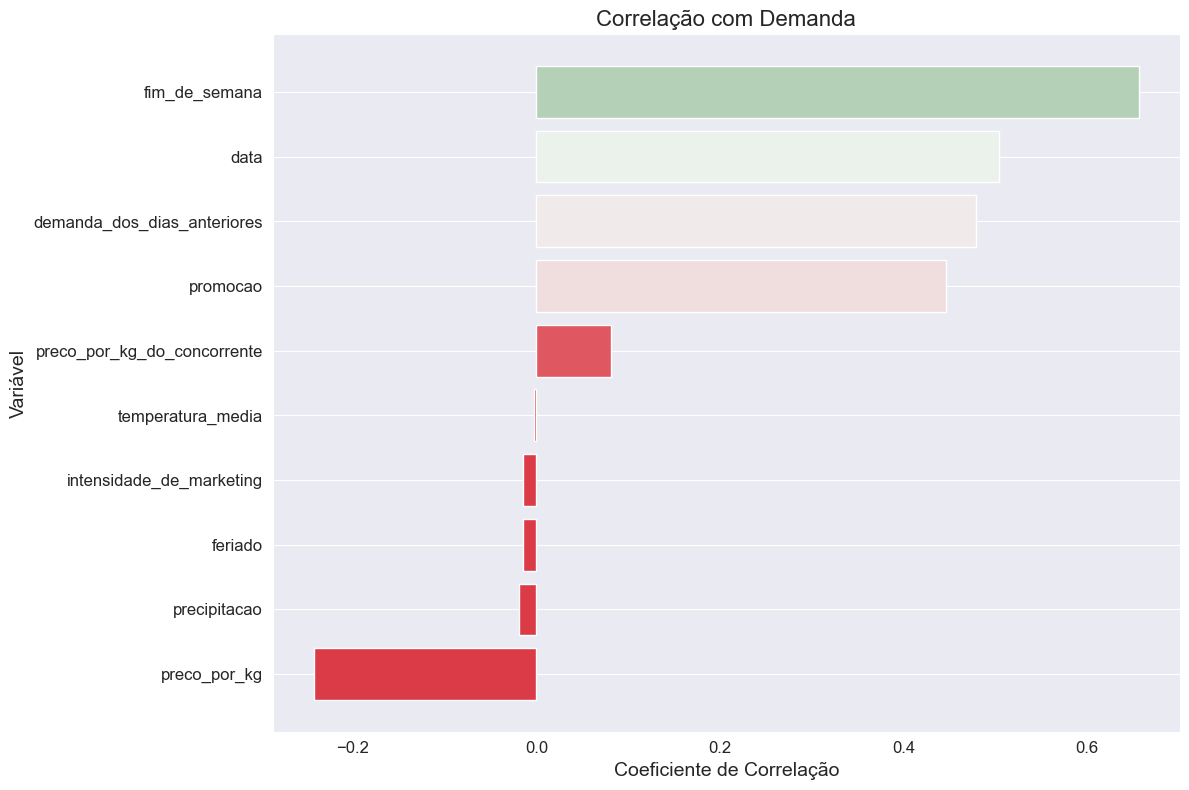

In [21]:
grafico1

**Como interpretar:** barras à direita (correlação positiva) indicam que, quando a variável aumenta, a demanda tende a aumentar. Barras à esquerda (correlação negativa) indicam o contrário. Lembre-se: **correlação não implica causalidade** e mede apenas relações **lineares**.

### Análise de resíduos

O **resíduo** é a diferença entre o valor real e o valor previsto (`real - previsto`). Em um bom modelo de regressão, esperamos que os resíduos:

- fiquem **distribuídos aleatoriamente** em torno da linha zero (linha vermelha);
- **não apresentem padrões** (curvas, funis), o que indicaria que o modelo não capturou alguma relação nos dados.

In [22]:
# Função para plot dos resíduos do modelo
def plot_residuos(model, dvalid, valid_y, save_path = None):

    # Faz as previsões no conjunto de validação
    preds = model.predict(dvalid)

    # Calcula os resíduos (diferença entre valores reais e previstos)
    residuals = valid_y - preds

    # Define o estilo do gráfico para 'whitegrid'
    sns.set_style("whitegrid", {"axes.facecolor": "#c2c4c2", "grid.linewidth": 1.5})

    # Cria a figura do plot com tamanho definido
    fig = plt.figure(figsize = (12, 8))
    
    # Cria um gráfico de dispersão dos valores reais versus resíduos
    plt.scatter(valid_y, residuals, color = "blue", alpha = 0.5)
    
    # Adiciona uma linha horizontal em y=0
    plt.axhline(y = 0, color = "r", linestyle = "-")

    # Define o título e os rótulos dos eixos do gráfico
    plt.title("Resíduos x Valores Reais", fontsize = 16)
    plt.xlabel("Valores Reais", fontsize = 14)
    plt.ylabel("Resíduos", fontsize = 14)
    plt.xticks(fontsize = 14)
    plt.yticks(fontsize = 14)
    plt.grid(axis = "y")

    # Ajusta o layout para evitar sobreposição
    plt.tight_layout()

    # Salva o gráfico como um arquivo PNG, se um caminho for fornecido
    if save_path:
        plt.savefig(save_path, format = "png", dpi = 600)

    # Fecha a figura para liberar memória
    plt.close(fig)

    # Retorna a figura criada
    return fig

### Importância das variáveis

O XGBoost calcula a importância das variáveis de formas diferentes:

- **gain** (ganho): quanto, em média, cada variável melhora o modelo quando é usada em uma divisão da árvore. Usado com `gbtree` e `dart`.
- **weight** (peso): no booster linear (`gblinear`) não existem árvores, então a importância é baseada nos coeficientes do modelo.

In [23]:
# Função para plot da importância das variáveis
def plot_feature_importance(model, booster):

    # Cria a figura e o eixo para o plot com tamanho definido
    fig, ax = plt.subplots(figsize = (10, 8))
    
    # Define o tipo de importância como "weight" se o booster for "gblinear", caso contrário "gain"
    importance_type = "weight" if booster == "gblinear" else "gain"
    
    # Plot das importância das variáveis usando o XGBoost
    xgb.plot_importance(model,
                        importance_type = importance_type,
                        ax = ax,
                        title = f"Feature Importance baseada em {importance_type}")
    
    # Ajusta o layout para evitar sobreposição
    plt.tight_layout()
    
    # Fecha a figura para liberar memória
    plt.close(fig)

    # Retorna a figura criada
    return fig

## Criando o Experimento no MLflow

No MLflow, a organização segue uma hierarquia:

```
Experimento (ex.: "Projeto1")
 └── Run (execução) pai: "p1"  → melhor resultado da otimização
      ├── Run filha 1          → 1ª tentativa do Optuna
      ├── Run filha 2          → 2ª tentativa do Optuna
      └── ...
```

- **Experimento**: agrupa todas as execuções relacionadas a um mesmo problema.
- **Run (execução)**: uma execução de código que registra parâmetros, métricas, tags e artefatos.

In [24]:
# Função para criar o experimento
def cria_experimento(experiment_name):

    # Verifica se o experimento já existe pelo nome
    # Obs.: o operador ":=" (walrus) atribui o resultado à variável "experiment" e já testa seu valor no "if"
    if experiment := mlflow.get_experiment_by_name(experiment_name):
        # Se o experimento existir, retorna seu ID
        return experiment.experiment_id
    else:
        # Se o experimento não existir, cria um novo e retorna seu ID
        return mlflow.create_experiment(experiment_name)

In [25]:
# Cria o experimento (ou recupera o ID, caso ele já exista)
# Isso evita erro ao executar o notebook mais de uma vez
id_experimento_p1 = cria_experimento("Projeto1")

In [26]:
# Experimento criado
id_experimento_p1

'1'

Visualize no seu navegador: http://127.0.0.1:8282

In [27]:
# Define o experimento MLflow ativo atual
# A partir daqui, todas as runs serão registradas dentro deste experimento
mlflow.set_experiment(experiment_id = id_experimento_p1)

<Experiment: artifact_location='mlflow-artifacts:/1', creation_time=1792005153989, effective_trace_archival_retention=None, experiment_id='1', last_update_time=1792005153989, lifecycle_stage='active', name='Projeto1', tags={}, trace_location=None, workspace='default'>

<!-- Projeto Desenvolvido na Data Science Academy - www.datascienceacademy.com.br -->
## Pré-Processamento dos Dados Para o Experimento

Acompanhe o videobook no Capítulo 6 do curso.

In [28]:
# Separa em X e y
# X: variáveis preditoras (removemos a data e a própria variável alvo)
# y: variável alvo (o que queremos prever)
X = df.drop(columns = ["data", "demanda"])
y = df["demanda"]

In [29]:
# Divide os dados em treino e validação
# 75% dos dados para treinar o modelo e 25% para avaliar o desempenho em dados que o modelo não viu
# Dica: adicione random_state = 42 para obter sempre a mesma divisão (reprodutibilidade)
x_treino, x_valid, y_treino, y_valid = train_test_split(X, y, test_size = 0.25)

In [30]:
# Coloca os dados no formato de matriz do XGBoost
# DMatrix é a estrutura de dados interna do XGBoost, otimizada em memória e velocidade de treinamento
treino = xgb.DMatrix(x_treino, label = y_treino)
valid = xgb.DMatrix(x_valid, label = y_valid)

In [31]:
# Substitui o registro padrão do Optuna apenas para ERROR
# Sem isso, o Optuna imprimiria uma mensagem para cada uma das 500 tentativas
optuna.logging.set_verbosity(optuna.logging.ERROR)

## Definindo o Callback de Logging

Registro de retorno de chamada que informará quando uma nova iteração de teste melhorar a existente.

Um **callback** é uma função que o Optuna executa automaticamente **ao final de cada tentativa (*trial*)**. Aqui ele é usado para imprimir uma mensagem **somente quando uma tentativa supera o melhor resultado anterior**, mostrando o percentual de melhora. Assim acompanhamos a evolução da otimização sem poluir a saída com as 500 tentativas.

- `study`: o objeto do estudo Optuna (contém o melhor valor encontrado até agora).
- `frozen_trial`: a tentativa que acabou de ser concluída.
- `study.user_attrs`: um "dicionário" onde podemos guardar informações próprias — aqui guardamos o melhor valor anterior (`winner`).

In [32]:
# Função de callback
def callback(study, frozen_trial):

    # Obtém o valor atual do "winner" (vencedor) dos atributos do estudo
    winner = study.user_attrs.get("winner", None)

    # Verifica se há um novo melhor valor e se o "winner" não é igual ao melhor valor
    if study.best_value and winner != study.best_value:
        
        # Define o novo melhor valor como "winner"
        study.set_user_attr("winner", study.best_value)
        
        # Se havia um "winner" anterior
        if winner:
            
            # Calcula a porcentagem de melhoria em relação ao "winner" anterior
            improvement_percent = (abs(winner - study.best_value) / study.best_value) * 100
            
            # Imprime o número da tentativa, o valor alcançado e a porcentagem de melhoria
            print(
                f"Tentativa {frozen_trial.number} alcançou o valor: {frozen_trial.value} com "
                f"{improvement_percent: .4f}% de melhora na métrica de avaliação.")
        else:
            # Se não havia um "winner" anterior, imprime o número da tentativa inicial e o valor alcançado
            print(
                f"Tentativa inicial {frozen_trial.number} alcançou o valor: "
                f"{frozen_trial.value} na métrica de avaliação.")

## Definindo os Hiperparâmetros do XGBoost Para o Experimento

Acompanhe o videobook no Capítulo 6 do curso.

A função abaixo é a **função objetivo** do Optuna. A cada tentativa (*trial*), o Optuna:

1. **sugere** valores para os hiperparâmetros dentro dos intervalos definidos (`trial.suggest_...`);
2. treina um modelo XGBoost com esses valores;
3. calcula o erro (MSE) no conjunto de validação e o **retorna**.

O Optuna usa os resultados anteriores para escolher valores mais promissores nas próximas tentativas (por padrão com o algoritmo **TPE** – *Tree-structured Parzen Estimator*), o que é muito mais eficiente que testar combinações aleatórias ou todas as combinações (*grid search*).

| Hiperparâmetro | Significado | Intervalo |
|---|---|---|
| `booster` | Tipo de modelo: árvores (`gbtree`), linear (`gblinear`) ou árvores com *dropout* (`dart`) | categórico |
| `lambda` | Regularização L2 (penaliza pesos grandes, reduz overfitting) | 1e-8 a 1.0 (escala log) |
| `alpha` | Regularização L1 (pode zerar pesos de variáveis pouco úteis) | 1e-8 a 1.0 (escala log) |
| `max_depth` | Profundidade máxima de cada árvore (complexidade) | 1 a 9 |
| `eta` | Taxa de aprendizado (tamanho do passo a cada nova árvore) | 1e-8 a 1.0 (escala log) |
| `gamma` | Redução mínima de erro para criar uma nova divisão na árvore | 1e-8 a 1.0 (escala log) |
| `grow_policy` | Estratégia de crescimento: por nível (`depthwise`) ou por maior ganho (`lossguide`) | categórico |

> **Escala logarítmica (`log = True`)**: para parâmetros que variam em várias ordens de grandeza (ex.: 0.00000001 a 1), a busca em escala log explora de forma equilibrada valores pequenos e grandes.
>
> **Runs aninhadas (`nested = True`)**: cada tentativa vira uma run filha no MLflow, permitindo comparar todas as tentativas na interface web.

In [33]:
# Função para definir os hiperparâmetros que serão otimizados
def otimiza_hiperparametro(trial):
    
    # Inicia uma nova execução de MLflow
    with mlflow.start_run(nested = True):
        
        # Define os hiperparâmetros básicos do modelo
        params = {
            
            # Função alvo (objetivo)
            "objective": "reg:squarederror",
            
            # Métrica de avaliação
            "eval_metric": "rmse",
            
            # Tipo de booster (algoritmo de treinamento)
            "booster": trial.suggest_categorical("booster", ["gbtree", "gblinear", "dart"]),
            
            # Valor de lambda para regularização L2
            "lambda": trial.suggest_float("lambda", 1e-8, 1.0, log = True),
            
            # Valor de alpha para regularização L1
            "alpha": trial.suggest_float("alpha", 1e-8, 1.0, log = True),
        }

        # Se o booster for 'gbtree' ou 'dart', adiciona parâmetros específicos
        if params["booster"] == "gbtree" or params["booster"] == "dart":
            
            # Profundidade máxima da árvore
            params["max_depth"] = trial.suggest_int("max_depth", 1, 9)
            
            # Valor de eta (taxa de aprendizado)
            params["eta"] = trial.suggest_float("eta", 1e-8, 1.0, log=True)
            
            # Valor de gamma para regularização adicional
            params["gamma"] = trial.suggest_float("gamma", 1e-8, 1.0, log=True)
            
            # Política de crescimento das árvores
            params["grow_policy"] = trial.suggest_categorical(
                "grow_policy", ["depthwise", "lossguide"]
            )

        # Treina o modelo com os hiperparâmetros escolhidos
        bst = xgb.train(params, treino)
        
        # Faz previsões no conjunto de validação
        preds = bst.predict(valid)
        
        # Calcula o erro quadrático médio
        error = mean_squared_error(y_valid, preds)

        # Registra os parâmetros no MLflow
        mlflow.log_params(params)
        
        # Registra o MSE no MLflow
        mlflow.log_metric("mse", error)
        
        # Registra o RMSE no MLflow
        mlflow.log_metric("rmse", math.sqrt(error))

    # Retorna o erro calculado
    return error

## Executando o Experimento com MLflow e Optuna

In [34]:
# Nome para a execução (run pai) no MLflow
run_name = "p1"

A célula abaixo é o **coração do projeto**. Ela:

1. Abre a **run pai** (`p1`) no MLflow.
2. Cria o estudo Optuna com `direction = "minimize"` (queremos o **menor** erro).
3. Executa **500 tentativas**; cada uma vira uma **run filha** com seus parâmetros e métricas.
4. Registra na run pai os **melhores hiperparâmetros**, o **melhor MSE/RMSE** e **tags** descritivas.
5. Treina o **modelo final** com os melhores hiperparâmetros.
6. Salva os **gráficos** como artefatos.
7. Registra o **modelo** no MLflow e guarda sua URI na variável `model_uri`.

> **Atenção:** com 500 tentativas a execução pode levar alguns minutos. Para testes rápidos em sala, reduza `n_trials` (ex.: 50).

> **Observação sobre o MLflow 3.x:** nas versões mais recentes, o modelo é salvo como um *Logged Model* (pasta `mlartifacts/<id_experimento>/models/m-...`) e não mais dentro da pasta de artefatos da run. Por isso:
> - usamos o parâmetro `name` (o antigo `artifact_path` está **depreciado**);
> - obtemos a URI do modelo pelo retorno de `log_model` (`info_modelo.model_uri`, no formato `models:/m-...`).
>
> Usar `mlflow.get_artifact_uri("model")` no MLflow 3.x gera o erro `404 ... No such artifact: '.../artifacts/model'`.

In [35]:
# Inicia a execução de ajuste de hiperparâmetros (run pai)
with mlflow.start_run(experiment_id = id_experimento_p1, run_name = run_name, nested = True):
    
    # Cria um estudo Optuna para otimização de hiperparâmetros para minimizar a função alvo (função de erro)
    study = optuna.create_study(direction = "minimize")

    # Otimiza os hiperparâmetros com 500 tentativas, usando a função de callback
    # Cada tentativa chama a função otimiza_hiperparametro, que cria uma run filha no MLflow
    study.optimize(otimiza_hiperparametro, n_trials = 500, callbacks = [callback])

    # Registra os melhores hiperparâmetros encontrados no MLflow
    mlflow.log_params(study.best_params)
    
    # Registra o melhor valor de MSE encontrado no MLflow
    mlflow.log_metric("best_mse", study.best_value)
    
    # Calcula e registra o melhor valor de RMSE no MLflow
    # O RMSE está na mesma unidade da variável alvo (kg), o que facilita a interpretação
    mlflow.log_metric("best_rmse", math.sqrt(study.best_value))

    # Define tags para a execução no MLflow
    # Tags são metadados livres que ajudam a buscar e filtrar runs na interface do MLflow
    mlflow.set_tags(tags = {"project": "MLOps Projeto 1",
                            "optimizer_engine": "optuna",
                            "model_family": "xgboost",
                            "feature_set_version": 1})

    # Treina o modelo com os melhores parâmetros encontrados
    model = xgb.train(study.best_params, treino)

    # Registra o gráfico grafico1 no MLflow
    mlflow.log_figure(figure = grafico1, artifact_file = "grafico1.png")

    # Plota e registra a importância das variáveis no MLflow
    importances = plot_feature_importance(model, booster = study.best_params.get("booster"))
    mlflow.log_figure(figure = importances, artifact_file = "grafico2.png")

    # Plota e registra os resíduos no MLflow
    residuals = plot_residuos(model, valid, y_valid)
    mlflow.log_figure(figure = residuals, artifact_file = "grafico3.png")

    # Define o nome do modelo a ser registrado
    nome_modelo = "model"

    # Registra o modelo treinado no MLflow
    # - input_example: exemplo de entrada usado para inferir a assinatura (schema) do modelo
    # - model_format: formato de serialização do XGBoost ("ubj" = Universal Binary JSON)
    # - metadata: informações extras salvas junto com o modelo
    info_modelo = mlflow.xgboost.log_model(xgb_model = model,
                                         name = nome_modelo,
                                         input_example = x_treino.iloc[[0]],
                                         model_format = "ubj",
                                         metadata = {"model_data_version": 1})

    # Obtém a URI do modelo registrado (formato models:/m-...)
    model_uri = info_modelo.model_uri

🏃 View run adventurous-bug-25 at: http://127.0.0.1:8282/#/experiments/1/runs/ba051c66f9a54320a930e6a605e23afe
🧪 View experiment at: http://127.0.0.1:8282/#/experiments/1
Tentativa inicial 0 alcançou o valor: 19631.11264418388 na métrica de avaliação.
🏃 View run agreeable-cat-914 at: http://127.0.0.1:8282/#/experiments/1/runs/d1ff55daec4b41d4a2fe3b5a26d05ad5
🧪 View experiment at: http://127.0.0.1:8282/#/experiments/1
🏃 View run industrious-wasp-58 at: http://127.0.0.1:8282/#/experiments/1/runs/dd921dc795ce47c89c25eecba4b53520
🧪 View experiment at: http://127.0.0.1:8282/#/experiments/1
🏃 View run able-fly-850 at: http://127.0.0.1:8282/#/experiments/1/runs/67517a8d46714c2382086c8c4d5302cf
🧪 View experiment at: http://127.0.0.1:8282/#/experiments/1
Tentativa 3 alcançou o valor: 15518.292665307777 com  26.5030% de melhora na métrica de avaliação.
🏃 View run brawny-ram-330 at: http://127.0.0.1:8282/#/experiments/1/runs/f269b1d32e484a7fb9247bf05b68692b
🧪 View experiment at: http://127.0.0.1:8

Visualize no seu navegador: http://127.0.0.1:8282

**O que explorar na interface do MLflow:**

- Abra o experimento **Projeto1** e expanda a run **p1** para ver as runs filhas (uma por tentativa).
- Selecione várias runs e clique em **Compare** para comparar parâmetros e métricas (gráficos de coordenadas paralelas são ótimos para ver quais hiperparâmetros levam a menores erros).
- Na run **p1**, aba **Artifacts**, veja os gráficos salvos; na aba **Logged models** (MLflow 3.x), veja o modelo registrado com seus arquivos (`MLmodel`, `model.ubj`, `requirements.txt` etc.).

## Carregando o Modelo a Partir dos Artefatos

Aqui simulamos o que aconteceria em outro momento (ou em outra aplicação): **recuperar o modelo a partir do MLflow**, sem precisar treiná-lo novamente. Basta conhecer a sua URI.

Formatos comuns de URI no MLflow:

| URI | Significado |
|---|---|
| `models:/m-<id>` | Logged Model (MLflow 3.x) – é o formato retornado por `info_modelo.model_uri` |
| `runs:/<run_id>/<caminho>` | Artefato salvo dentro de uma run |
| `models:/<nome>/<versão>` | Modelo cadastrado no **Model Registry** |

In [36]:
# Caminho (URI) para o melhor modelo (com melhor combinação de hiperparâmetros) registrado no MLflow
model_uri

'models:/m-5b7599fa032a455aab3d5b2739b72860'

In [37]:
# Carrega o melhor modelo a partir do MLflow
# O MLflow baixa os arquivos do servidor e reconstrói o objeto Booster do XGBoost
# Caso o kernel tenha sido reiniciado, defina a URI manualmente (copie o ID do modelo na interface do MLflow):
# model_uri = "models:/m-<id_do_modelo>"
melhor_modelo = mlflow.xgboost.load_model(model_uri)

## Pipeline de Inferência com o Melhor Modelo

**Inferência** é o uso do modelo treinado para gerar previsões. Aqui fazemos uma inferência em **lote** (*batch*) dentro do próprio notebook.

> **Isto NÃO é deploy!** Fazer deploy significa disponibilizar o modelo para uso por outros sistemas (por exemplo, via API REST com `mlflow models serve`, contêineres Docker ou serviços em nuvem), com monitoramento e controle de versões. Esse é o tema dos próximos projetos.
>
> **Observação didática:** estamos prevendo sobre **todo** o `X`, incluindo os dados usados no treinamento. Para avaliar o desempenho real do modelo, devemos usar apenas dados que ele **não viu** (como o conjunto de validação ou novos dados).

In [38]:
# Gera um batch de dados a partir de X (variáveis preditoras)
# O Booster do XGBoost espera os dados no formato DMatrix
batch_dmatrix = xgb.DMatrix(X)

In [39]:
# Faz a inferência (previsões) usando o melhor modelo - ATENÇÃO: ISSO NÃO É DEPLOY!!!!
# O resultado é um array NumPy com uma previsão de demanda para cada linha de X
inferencia = melhor_modelo.predict(batch_dmatrix)

In [40]:
# Cria cópia do dataframe original (evita alterar o df usado nas etapas anteriores)
df_final = df.copy()

In [41]:
# Cria uma coluna com as previsões (lado a lado com a demanda real, para comparação)
df_final["demanda_prevista"] = inferencia

In [42]:
# Exibe 10 linhas aleatórias para comparar "demanda" (real) com "demanda_prevista"
df_final.sample(10)

,data,temperatura_media,precipitacao,fim_de_semana,feriado,preco_por_kg,promocao,demanda,demanda_dos_dias_anteriores,preco_por_kg_do_concorrente,intensidade_de_marketing,demanda_prevista
4576,2023-04-29 09:16:07.878651,24.443984,1.958565,1,0,1.032026,1,2032.921506,1503.656698,1.743206,0.813058,1764.179932
3261,2019-09-22 09:16:07.880235,24.006178,1.742436,1,0,1.394744,0,1553.428491,1546.356518,2.566924,0.917048,1539.444214
3097,2019-04-11 09:16:07.880406,20.394686,4.702431,0,0,0.510217,1,1436.014373,1343.276504,2.978784,0.869998,1436.231567
4170,2022-03-19 09:16:07.879173,31.957239,12.782066,1,0,1.495902,0,1538.917738,1150.347938,1.463146,0.703888,1432.167236
3225,2019-08-17 09:16:07.880272,10.034460,0.788068,1,0,2.088275,0,1447.000945,1209.046302,0.843685,0.924240,1370.407593
1492,2014-11-18 09:16:07.882109,29.628042,1.330795,0,0,2.368003,0,954.448193,1027.427272,1.618505,0.910498,956.610291
2144,2016-08-31 09:16:07.881407,11.149498,0.620173,0,0,1.211290,0,1088.557826,989.979645,1.129555,0.942601,1040.269165
1851,2015-11-12 09:16:07.881728,27.016179,6.740984,0,0,2.434733,1,1207.508610,1055.188415,1.357328,0.990809,1163.447021
3816,2021-03-30 09:16:07.879621,12.266509,6.202462,0,0,2.123043,0,1006.549351,1145.903908,1.283260,0.991361,1058.147949
4448,2022-12-22 09:16:07.878822,27.186521,7.841008,0,0,1.356446,0,1298.182449,1113.126147,1.668500,0.952854,1149.190796


## Resumo da Aula

- Iniciamos um **servidor MLflow** com backend store (`mlflow.db`) e artifact store (`mlartifacts/`).
- Organizamos o trabalho em um **experimento** com uma **run pai** e **runs filhas** (uma por tentativa).
- Usamos o **Optuna** para buscar automaticamente os melhores hiperparâmetros do **XGBoost**.
- Registramos **parâmetros, métricas, tags, gráficos e o modelo** no MLflow.
- **Recarregamos o modelo** a partir da sua URI e fizemos uma **inferência em lote**.

## Exercícios Sugeridos

1. Adicione `random_state = 42` ao `train_test_split` e execute o experimento duas vezes. Os resultados ficam iguais? Por quê?
2. Reduza `n_trials` para 50 e compare o melhor RMSE com o obtido com 500 tentativas. Vale a pena o custo computacional extra?
3. Inclua um novo hiperparâmetro na busca (ex.: `subsample` ou `min_child_weight`) e analise o impacto na interface do MLflow.
4. Calcule o RMSE apenas no conjunto de validação usando `melhor_modelo` e compare com o `best_rmse` registrado no MLflow.
5. Registre o modelo no **Model Registry** com `mlflow.register_model(model_uri, "modelo_demanda")` e carregue-o com `models:/modelo_demanda/1`.

In [43]:
# Registra o autor do notebook
%reload_ext watermark
%watermark -a "Prof. Dr. Marcos Hoffmann"

Author: Prof. Dr. Marcos Hoffmann



In [44]:
# Versão do Python e informações da máquina (sistema operacional, CPU)
%watermark -v -m

Python implementation: CPython
Python version       : 3.12.2
IPython version      : 9.5.0

Compiler    : Clang 16.0.6 
OS          : Darwin
Release     : 27.2.0
Machine     : arm64
Processor   : arm
CPU cores   : 14
Architecture: 64bit



In [45]:
# Versões dos pacotes importados neste notebook (importante para reprodutibilidade)
%watermark --iversions

json      : 2.0.9
matplotlib: 3.10.6
mlflow    : 3.16.0
numpy     : 1.26.4
optuna    : 5.0.0
pandas    : 2.2.2
seaborn   : 0.13.2
sklearn   : 1.5.2
xgboost   : 3.0.3

